# Pharos 02 - Demand forecasting

Per group gradient boosted trees predict next day demand from recent lags, rolling statistics and calendar features. Accuracy is measured against two transparent baselines on a held out tail.

In [1]:
import sys, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'font.size':10})
sys.path.insert(0, '../backend')
from app.features import build_matrix, FEATURE_NAMES, forecast_recursive
from xgboost import XGBRegressor

CATS = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']
df = pd.read_csv('../data/salesdaily.csv'); df['datum']=pd.to_datetime(df['datum'], format='%m/%d/%Y')
df = df.set_index('datum').sort_index()[CATS].astype(float)
print('features:', len(FEATURE_NAMES)); FEATURE_NAMES

features: 17


['dow',
 'month',
 'weekofyear',
 'is_weekend',
 'doy_sin',
 'doy_cos',
 'lag_1',
 'lag_7',
 'lag_14',
 'lag_28',
 'roll_mean_7',
 'roll_mean_14',
 'roll_mean_28',
 'roll_std_7',
 'roll_std_14',
 'roll_std_28',
 'same_dow_mean_4']

### Backtest on one group
We hold out the last 120 days and predict one step ahead, the way the service re-forecasts each day as yesterday's actuals arrive.

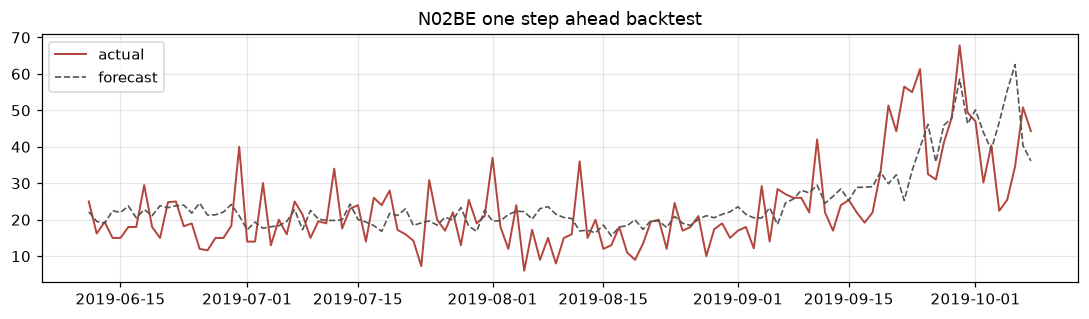

In [2]:
def model():
    return XGBRegressor(n_estimators=450, max_depth=4, learning_rate=0.045, subsample=.85,
                        colsample_bytree=.85, min_child_weight=3, reg_lambda=1.2,
                        objective='reg:squarederror', random_state=42, n_jobs=4)

cat='N02BE'; TEST=120
X,y,dates = build_matrix(df[cat]); split=len(X)-TEST
m = model(); m.fit(X[:split], y[:split])
pred = np.clip(m.predict(X[split:]), 0, None); yte=y[split:]; dte=dates[split:]

fig, ax = plt.subplots(figsize=(10,3))
ax.plot(dte, yte, color='#b4463c', lw=1.3, label='actual')
ax.plot(dte, pred, color='#555', lw=1.1, ls='--', label='forecast')
ax.set_title(f'{cat} one step ahead backtest'); ax.legend(); plt.tight_layout()

### Baselines and metrics across all groups
Persistence = yesterday. Seasonal naive = same weekday last week. Skill is the reduction in MAE versus seasonal naive.

In [3]:
def metrics(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float); e=p-a; mk=a>1e-6
    return dict(mae=round(float(np.mean(abs(e))),3),
                rmse=round(float(np.sqrt(np.mean(e**2))),3),
                mape=round(float(np.mean(abs(e[mk]/a[mk]))*100),1))

rows=[]
for c in CATS:
    X,y,dates=build_matrix(df[c]); split=len(X)-TEST
    mm=model(); mm.fit(X[:split],y[:split]); pr=np.clip(mm.predict(X[split:]),0,None)
    yt=y[split:]; dt=dates[split:]
    nv=np.nan_to_num(df[c].reindex(dt-pd.Timedelta(days=1)).to_numpy(), nan=df[c].mean())
    sn=np.nan_to_num(df[c].reindex(dt-pd.Timedelta(days=7)).to_numpy(), nan=df[c].mean())
    mo,mn,ms=metrics(yt,pr),metrics(yt,nv),metrics(yt,sn)
    rows.append(dict(group=c, model_mae=mo['mae'], seasonal_naive_mae=ms['mae'],
                     persistence_mae=mn['mae'], skill_pct=round((1-mo['mae']/ms['mae'])*100,1)))
res=pd.DataFrame(rows).set_index('group'); res

,model_mae,seasonal_naive_mae,persistence_mae,skill_pct
group,,,,
M01AB,2.478,3.331,3.441,25.6
M01AE,1.517,2.012,2.072,24.6
N02BA,1.439,1.965,1.902,26.8
N02BE,7.014,8.863,7.985,20.9
N05B,2.929,3.723,3.872,21.3
N05C,0.850,1.167,1.100,27.2
R03,4.062,5.000,4.633,18.8
R06,1.666,2.585,2.324,35.6


Average MAE skill vs seasonal naive: +25.1%


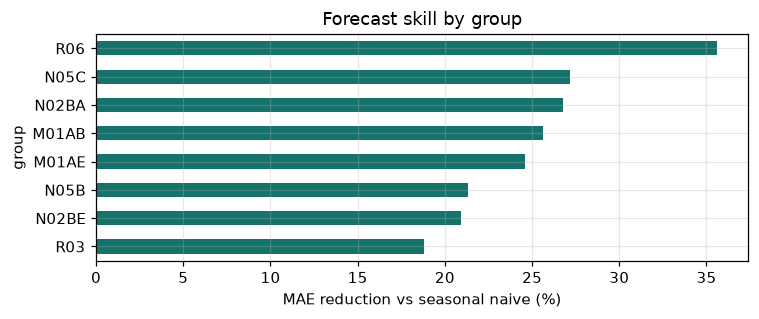

In [4]:
print('Average MAE skill vs seasonal naive: %+.1f%%' % res['skill_pct'].mean())
ax=res['skill_pct'].sort_values().plot.barh(color='#15736b', figsize=(7,3))
ax.set_xlabel('MAE reduction vs seasonal naive (%)'); ax.set_title('Forecast skill by group'); plt.tight_layout()

### Which features matter

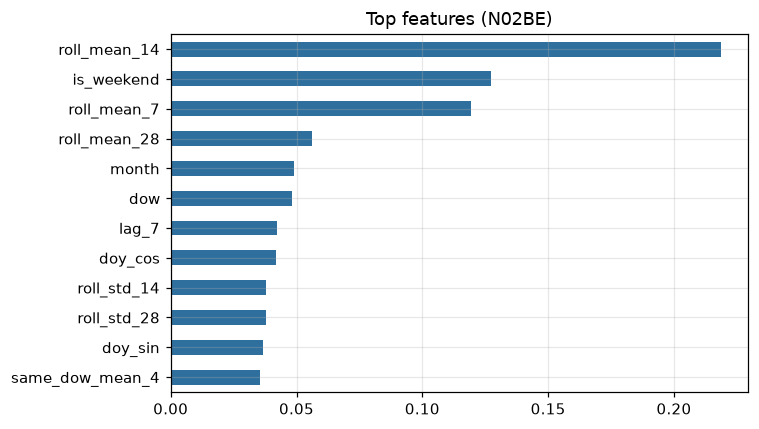

In [5]:
X,y,_=build_matrix(df['N02BE']); fm=model(); fm.fit(X,y)
imp=pd.Series(fm.feature_importances_, index=FEATURE_NAMES).sort_values().tail(12)
imp.plot.barh(color='#2e6f9e', figsize=(7,4)); plt.title('Top features (N02BE)'); plt.tight_layout()

### 30 day outlook
The serving model is refit on the full series, then rolled forward day by day, feeding each prediction back as the next lag.

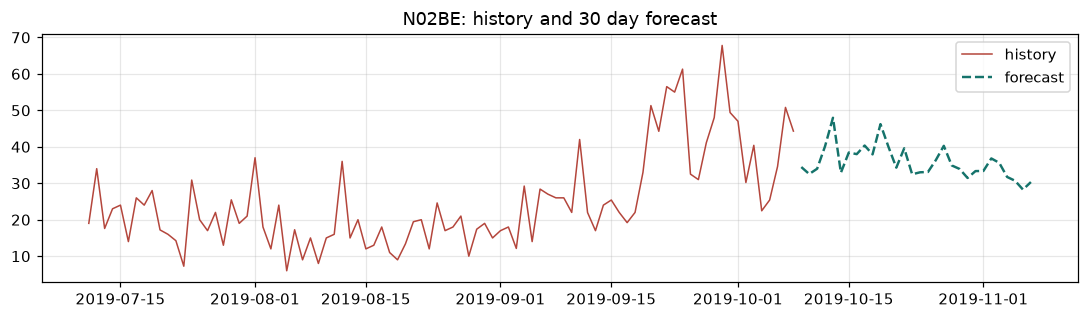

In [6]:
import joblib
bundle=joblib.load('../backend/artifacts/forecast_models.joblib')
fc=forecast_recursive(bundle['models']['N02BE'], df['N02BE'], 30)
fig,ax=plt.subplots(figsize=(10,3))
ax.plot(df['N02BE'].tail(90).index, df['N02BE'].tail(90), color='#b4463c', lw=1, label='history')
ax.plot(fc.index, fc.values, color='#15736b', lw=1.6, ls='--', label='forecast')
ax.legend(); ax.set_title('N02BE: history and 30 day forecast'); plt.tight_layout()

**Result.** The model lowers MAE by about 25 percent against the seasonal naive baseline on average, with the largest gains on the seasonal groups. MAPE is high only where daily counts are tiny, where percentage error is not a meaningful scale, so MAE is the headline metric.